<a href="https://colab.research.google.com/github/esra-ylmz8572tech/ArabaYarisi/blob/master/alistirma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle
from google.colab import files
files.upload()   # kaggle.json dosyasını seç
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
!kaggle datasets download -d lincolnzh/martianlunar-crater-detection-dataset


Dataset URL: https://www.kaggle.com/datasets/lincolnzh/martianlunar-crater-detection-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 74.0M/74.0M [00:01<00:00, 65.5MB/s]



In [ ]:
!unzip -q martianlunar-crater-detection-dataset.zip -d dataset/


In [ ]:
!ls dataset/

best.pt  craters


In [ ]:
!ls dataset/craters


test  train  valid


In [ ]:
import os
print("Train klasörü içindekiler:", os.listdir('dataset/craters/train'))


Train klasörü içindekiler: ['labels', 'labels.cache', 'images']


In [ ]:
import os
import shutil
import random

# Rastgelelik için tohum (seed) sabitleyelim (tekrarlanabilirlik için)
random.seed(42)

# Eski hatalı dönüştürme klasörünü silelim
if os.path.exists('dataset_cls'):
    shutil.rmtree('dataset_cls')

# 1. Tüm görselleri tarayıp crater / no_crater olarak listeleyelim
all_craters = []
all_no_craters = []

base_src = 'dataset/craters'
for split in ['train', 'valid', 'test']:
    src_img_dir = os.path.join(base_src, split, 'images')
    src_lbl_dir = os.path.join(base_src, split, 'labels')

    if os.path.exists(src_img_dir):
        for img_name in os.listdir(src_img_dir):
            if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            img_path = os.path.join(src_img_dir, img_name)
            txt_name = os.path.splitext(img_name)[0] + '.txt'
            txt_path = os.path.join(src_lbl_dir, txt_name)

            if os.path.exists(txt_path) and os.path.getsize(txt_path) > 0:
                all_craters.append(img_path)
            else:
                all_no_craters.append(img_path)

# 2. Listeleri karıştıralım
random.shuffle(all_craters)
random.shuffle(all_no_craters)

# 3. Görselleri Train (%70), Valid (%15), Test (%15) oranında bölelim
def split_data(file_list):
    n = len(file_list)
    train_end = int(n * 0.70)
    val_end = train_end + int(n * 0.15)

    return {
        'train': file_list[:train_end],
        'valid': file_list[train_end:val_end],
        'test': file_list[val_end:]
    }

crater_splits = split_data(all_craters)
no_crater_splits = split_data(all_no_craters)

# 4. Dosyaları yeni klasör yapısına kopyalayalım
for split in ['train', 'valid', 'test']:
    for cls_name, files in [('crater', crater_splits[split]), ('no_crater', no_crater_splits[split])]:
        target_dir = os.path.join('dataset_cls', split, cls_name)
        os.makedirs(target_dir, exist_ok=True)
        for src_file in files:
            img_name = os.path.basename(src_file)
            shutil.copy(src_file, os.path.join(target_dir, img_name))

print("✅ Yeni veri bölümü başarıyla tamamlandı!")
for split in ['train', 'valid', 'test']:
    c_count = len(os.listdir(f'dataset_cls/{split}/crater'))
    nc_count = len(os.listdir(f'dataset_cls/{split}/no_crater'))
    print(f"{split.upper()} -> Crater: {c_count} | No-Crater: {nc_count}")

✅ Yeni veri bölümü başarıyla tamamlandı!
TRAIN -> Crater: 92 | No-Crater: 7
VALID -> Crater: 19 | No-Crater: 1
TEST -> Crater: 21 | No-Crater: 3


In [ ]:
import os
import shutil

splits = ['train', 'valid', 'test']
base_src = 'dataset/craters'
base_dst = 'dataset_cls'

for split in splits:
    src_img_dir = os.path.join(base_src, split, 'images')
    src_lbl_dir = os.path.join(base_src, split, 'labels')

    crater_dst = os.path.join(base_dst, split, 'crater')
    no_crater_dst = os.path.join(base_dst, split, 'no_crater')

    os.makedirs(crater_dst, exist_ok=True)
    os.makedirs(no_crater_dst, exist_ok=True)

    if os.path.exists(src_img_dir):
        for img_name in os.listdir(src_img_dir):
            if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            img_path = os.path.join(src_img_dir, img_name)
            txt_name = os.path.splitext(img_name)[0] + '.txt'
            txt_path = os.path.join(src_lbl_dir, txt_name)

            # Etiket dosyası var mı ve içi dolu mu?
            if os.path.exists(txt_path) and os.path.getsize(txt_path) > 0:
                shutil.copy(img_path, os.path.join(crater_dst, img_name))
            else:
                shutil.copy(img_path, os.path.join(no_crater_dst, img_name))

print("✅ Veri kümesi başarıyla sınıflandırma formatına dönüştürüldü!")
print("Dönüştürülen Train Sınıfları:", os.listdir('dataset_cls/train'))
print(f"Train Crater sayısı: {len(os.listdir('dataset_cls/train/crater'))}")
print(f"Train No-Crater sayısı: {len(os.listdir('dataset_cls/train/no_crater'))}")

✅ Veri kümesi başarıyla sınıflandırma formatına dönüştürüldü!
Dönüştürülen Train Sınıfları: ['crater', 'no_crater']
Train Crater sayısı: 89
Train No-Crater sayısı: 9


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Transforms & Augmentation
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Dataset'lerin Yüklenmesi
train_dataset = datasets.ImageFolder(root='dataset_cls/train', transform=train_transforms)
valid_dataset = datasets.ImageFolder(root='dataset_cls/valid', transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(root='dataset_cls/test',  transform=val_test_transforms)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"\n✅ Eğitim görsel sayısı: {len(train_dataset)}")
print(f"✅ Doğrulama görsel sayısı: {len(valid_dataset)}")
print(f"✅ Test görsel sayısı: {len(test_dataset)}")
print(f"✅ Sınıflar: {train_dataset.classes}")


✅ Eğitim görsel sayısı: 99
✅ Doğrulama görsel sayısı: 20
✅ Test görsel sayısı: 24
✅ Sınıflar: ['crater', 'no_crater']


In [ ]:
import matplotlib.pyplot as plt

# GPU/CPU kontrolü
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SimpleCNN Mimarisi
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=len(train_dataset.classes)):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 10 Epoch Eğitim Döngüsü
EPOCHS = 10
train_losses, val_losses = [], []
val_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Validation (Doğrulama) Fazı
    model.eval()
    running_val_loss = 0.0
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / len(valid_dataset)
    epoch_val_acc = 100 * correct / total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: %{epoch_val_acc:.2f}")

Epoch [1/10] -> Train Loss: 0.7801 | Val Loss: 0.2337 | Val Acc: %95.00
Epoch [2/10] -> Train Loss: 0.3094 | Val Loss: 0.2607 | Val Acc: %95.00
Epoch [3/10] -> Train Loss: 0.2669 | Val Loss: 0.2124 | Val Acc: %95.00
Epoch [4/10] -> Train Loss: 0.3630 | Val Loss: 0.2015 | Val Acc: %95.00
Epoch [5/10] -> Train Loss: 0.2844 | Val Loss: 0.1975 | Val Acc: %95.00
Epoch [6/10] -> Train Loss: 0.2698 | Val Loss: 0.2146 | Val Acc: %95.00
Epoch [7/10] -> Train Loss: 0.2788 | Val Loss: 0.2293 | Val Acc: %95.00
Epoch [8/10] -> Train Loss: 0.2513 | Val Loss: 0.1860 | Val Acc: %95.00
Epoch [9/10] -> Train Loss: 0.2839 | Val Loss: 0.1840 | Val Acc: %95.00
Epoch [10/10] -> Train Loss: 0.2580 | Val Loss: 0.2144 | Val Acc: %95.00


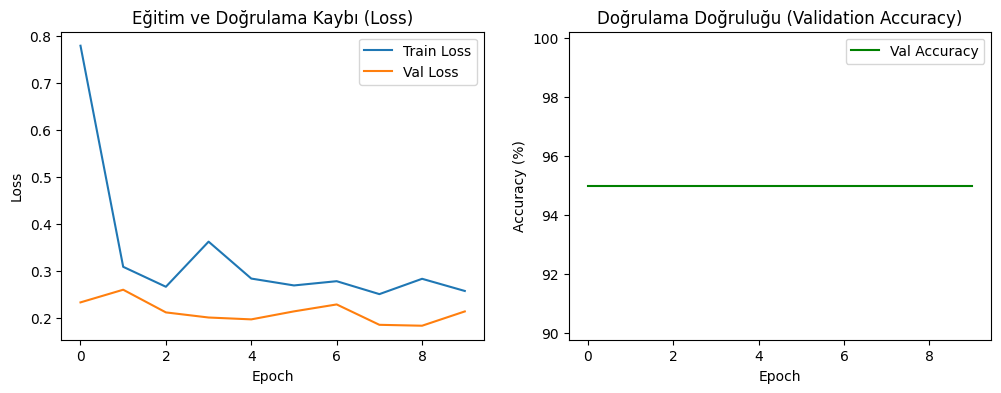


🎯 TEST KÜMESİ SONUCU -> Başarı Oranı: %87.50


In [ ]:
# 1. Eğitim Grafikleri
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Eğitim ve Doğrulama Kaybı (Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Val Accuracy', color='green')
plt.title('Doğrulama Doğruluğu (Validation Accuracy)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.show()

# 2. Test Kümesini Değerlendirme (6. Adım)
model.eval()
test_correct, test_total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
print(f"\n🎯 TEST KÜMESİ SONUCU -> Başarı Oranı: %{test_acc:.2f}")

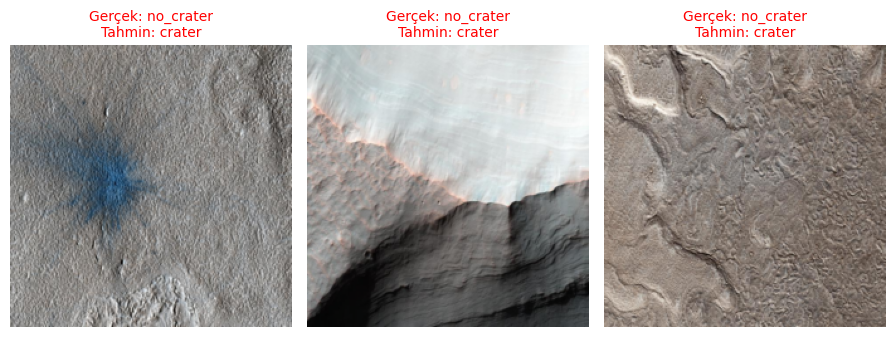

In [ ]:
import numpy as np

model.eval()
misclassified_images = []
misclassified_labels = []
misclassified_preds = []

# Yanlış tahminleri topla
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        for i in range(len(labels)):
            if predicted[i] != labels[i]:
                # Tensor'u numpy array'e çevir ve CPU'ya al
                img = images[i].cpu().numpy().transpose((1, 2, 0))
                # Normalizasyonu geri al
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)

                misclassified_images.append(img)
                misclassified_labels.append(labels[i].item())
                misclassified_preds.append(predicted[i].item())

# Sınıf isimlerini al
class_names = test_dataset.classes

# Hatalı görselleri çizdir
num_mistakes = len(misclassified_images)
if num_mistakes > 0:
    plt.figure(figsize=(15, 5))
    for i in range(min(num_mistakes, 5)):
        plt.subplot(1, 5, i+1)
        plt.imshow(misclassified_images[i])
        true_label = class_names[misclassified_labels[i]]
        pred_label = class_names[misclassified_preds[i]]
        plt.title(f"Gerçek: {true_label}\nTahmin: {pred_label}", color='red', fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Hiç hata yok!")


In [ ]:
from google.colab import files
import torch

# Modelin öğrendiği ağırlıkları kaydetme
torch.save(model.state_dict(), 'rover_crater_model.pth')
print("Model başarıyla 'rover_crater_model.pth' olarak kaydedildi!")

# Dosyayı otomatik olarak bilgisayarına indirme
files.download('rover_crater_model.pth')

Model başarıyla 'rover_crater_model.pth' olarak kaydedildi!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>